In [1]:
import sys
sys.path.append("..")
import pandas as pd
from src.data_loader import load_orders

orders = load_orders()
print(orders.shape)
orders.head()

(99441, 24)


,order_id,customer_unique_id,state,order_status,purchase_ts,approved_ts,delivered_ts,estimated_ts,n_items,n_sellers,...,avg_photos,avg_desc_len,payment_value,installments,payment_type,n_payments,used_voucher,review_score,has_comment,comment_len
0,2e7a8482f6fb09756ca50c10d7bfc047,b7d76e111c89f7ebf14761390f0f7d17,RR,shipped,2016-09-04 21:15:19,2016-10-07 13:18:03,NaT,2016-10-20,2.0,1.0,...,2.5,590.0,136.23,1.0,credit_card,1.0,0.0,1.0,1.0,51.0
1,e5fa5a7210941f7d56d0208e4e071d35,4854e9b3feff728c13ee5fc7d1547e92,RS,canceled,2016-09-05 00:15:34,2016-10-07 13:17:15,NaT,2016-10-28,1.0,1.0,...,1.0,381.0,75.06,3.0,credit_card,1.0,0.0,1.0,1.0,125.0
2,809a282bbd5dbcabb6f2f724fca862ec,009b0127b727ab0ba422f6d9604487c7,SP,canceled,2016-09-13 15:24:19,2016-10-07 13:16:46,NaT,2016-09-30,NaN,NaN,...,NaN,NaN,40.95,2.0,credit_card,1.0,0.0,1.0,1.0,61.0
3,bfbd0f9bdef84302105ad712db648a6c,830d5b7aaa3b6f1e9ad63703bec97d23,SP,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-09 07:47:38,2016-10-04,3.0,1.0,...,1.0,1036.0,NaN,NaN,NaN,NaN,NaN,1.0,1.0,46.0
4,71303d7e93b399f5bcd537d124c0bcfa,0eb1ee9dba87f5b36b4613a65074337c,SP,canceled,2016-10-02 22:07:52,2016-10-06 15:50:56,NaT,2016-10-25,1.0,1.0,...,1.0,561.0,109.34,1.0,credit_card,1.0,0.0,1.0,0.0,0.0


In [2]:
#Imports and charts
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4)

In [3]:
df = orders.copy()

# 1. Remove orders that never became real purchases
df = df[~df["order_status"].isin(["canceled", "unavailable"])].copy()

# 2. Remove duplicate orders (should be none)
print("duplicates:", df["order_id"].duplicated().sum())
df = df.drop_duplicates("order_id")

# 3. New columns
df["delivery_days"] = (df["delivered_ts"] - df["purchase_ts"]).dt.total_seconds() / 86400
df["is_late"] = (df["delivered_ts"] > df["estimated_ts"]).astype("float")
df.loc[df["delivered_ts"].isna(), "is_late"] = np.nan
df["month"] = df["purchase_ts"].dt.to_period("M").dt.to_timestamp()

# 4. Keep complete months only (2016 and the last months are sparse)
df = df[(df["purchase_ts"] >= "2017-01-01") & (df["purchase_ts"] < "2018-09-01")]

print(df.shape)
df.describe().round(2)

duplicates: 0
(97910, 27)


,purchase_ts,approved_ts,delivered_ts,estimated_ts,n_items,n_sellers,items_value,freight_value,avg_weight_g,avg_photos,...,payment_value,installments,n_payments,used_voucher,review_score,has_comment,comment_len,delivery_days,is_late,month
count,97910,97891,96203,97910,97905.00,97905.00,97905.00,97905.00,97889.00,96532.00,...,97910.00,97910.00,97910.00,97910.00,97181.00,97181.00,97181.00,96203.00,96203.00,97910
mean,2018-01-02 10:19:41.533142,2018-01-02 21:44:09.677539,2018-01-15 18:17:55.145837,2018-01-26 02:40:14.217138,1.14,1.01,137.37,22.82,2102.25,2.25,...,160.22,2.93,1.04,0.04,4.12,0.41,27.85,12.54,0.08,2017-12-18 06:08:53.436830
min,2017-01-05 11:56:06,2017-01-05 12:10:17,2017-01-11 13:14:05,2017-02-01 00:00:00,1.00,1.00,0.85,0.00,0.00,1.00,...,9.59,0.00,1.00,0.00,1.00,0.00,0.00,0.53,0.00,2017-01-01 00:00:00
25%,2017-09-14 11:13:37,2017-09-14 19:25:02.500000,2017-09-26 21:48:49.500000,2017-10-05 00:00:00,1.00,1.00,45.90,13.86,300.00,1.00,...,61.99,1.00,1.00,0.00,4.00,0.00,0.00,6.76,0.00,2017-09-01 00:00:00
50%,2018-01-20 15:30:05,2018-01-20 22:02:10,2018-02-03 03:17:23,2018-02-16 00:00:00,1.00,1.00,86.90,17.18,700.00,2.00,...,105.28,2.00,1.00,0.00,5.00,0.00,0.00,10.21,0.00,2018-01-01 00:00:00
75%,2018-05-05 10:38:17.500000,2018-05-05 17:10:15,2018-05-16 12:59:53,2018-05-28 00:00:00,1.00,1.00,149.90,24.04,1813.00,3.00,...,176.71,4.00,1.00,0.00,5.00,1.00,41.00,15.68,0.00,2018-05-01 00:00:00
max,2018-08-29 15:00:37,2018-08-29 15:10:26,2018-10-17 13:22:46,2018-10-25 00:00:00,21.00,5.00,13440.00,1794.96,40425.00,20.00,...,13664.08,24.00,29.00,1.00,5.00,1.00,208.00,209.63,1.00,2018-08-01 00:00:00
std,NaN,NaN,NaN,NaN,0.54,0.12,209.39,21.65,3755.13,1.74,...,219.20,2.71,0.38,0.19,1.32,0.49,47.86,9.53,0.27,NaN


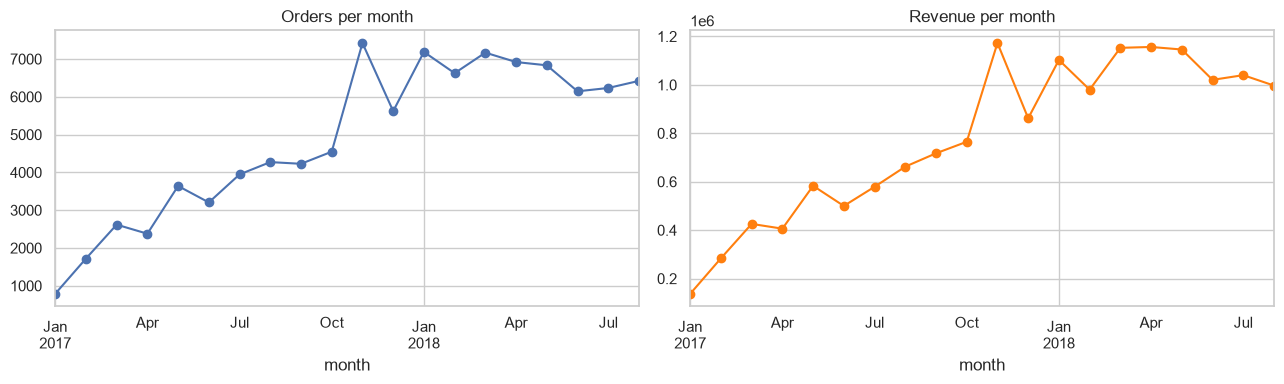

In [4]:
#Orders and revenue per month
monthly = df.groupby("month").agg(orders=("order_id", "count"),
                                  revenue=("payment_value", "sum"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
monthly["orders"].plot(ax=ax[0], marker="o", title="Orders per month")
monthly["revenue"].plot(ax=ax[1], marker="o", color="tab:orange", title="Revenue per month")
plt.tight_layout(); plt.show()

In [5]:
#How many customers come back?
orders_per_customer = df.groupby("customer_unique_id").size()
print(orders_per_customer.value_counts().sort_index())
print("repeat share:", round((orders_per_customer > 1).mean(), 4))

1     91832
2      2640
3       187
4        29
5         9
6         5
7         3
9         1
16        1
Name: count, dtype: int64
repeat share: 0.0304


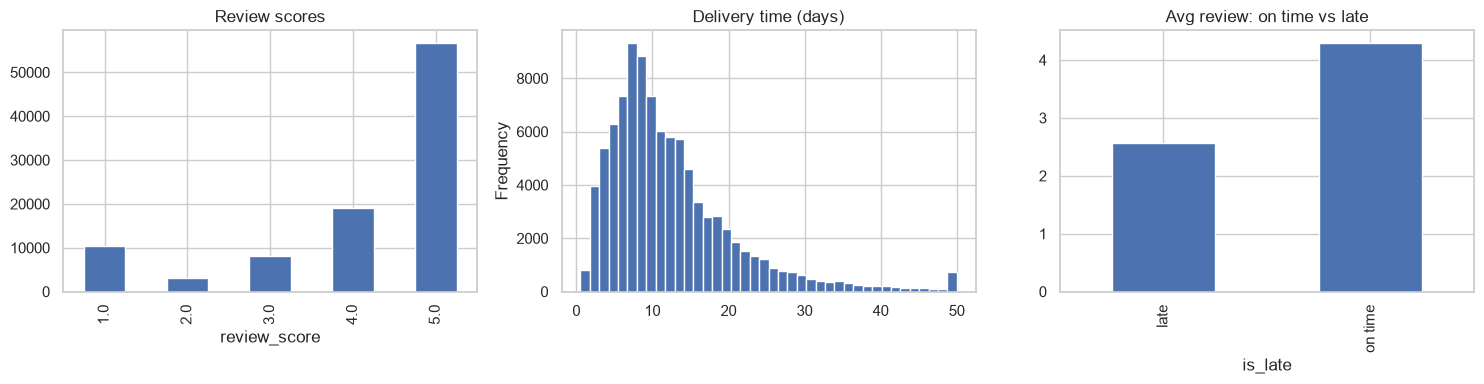

late share: 0.081


In [6]:
#Delivery and reviews
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df["review_score"].round().value_counts().sort_index().plot.bar(ax=ax[0], title="Review scores")
df["delivery_days"].clip(upper=50).plot.hist(bins=40, ax=ax[1], title="Delivery time (days)")
df.groupby(df["is_late"].map({0.0: "on time", 1.0: "late"}))["review_score"].mean().plot.bar(
    ax=ax[2], title="Avg review: on time vs late")
plt.tight_layout(); plt.show()
print("late share:", round(df["is_late"].mean(), 3))

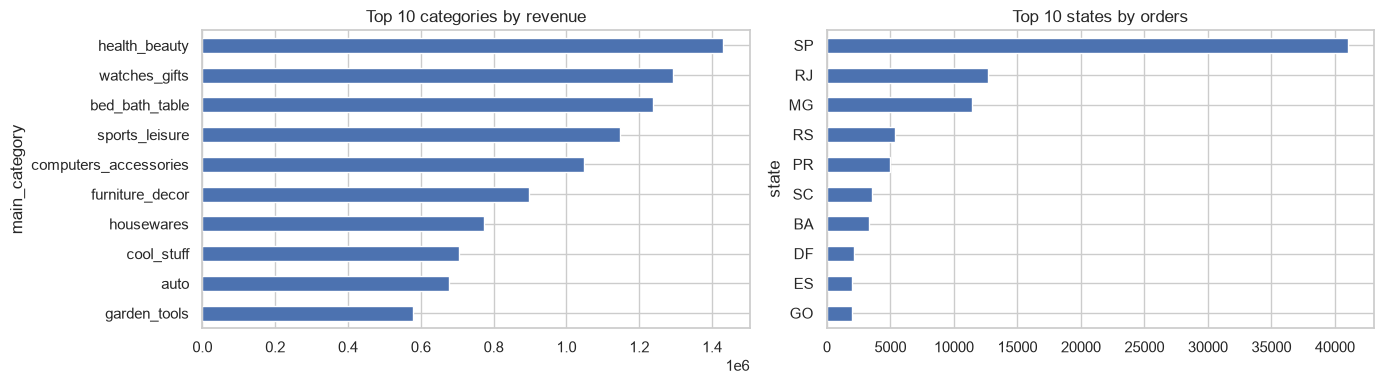

In [7]:
#Category and state
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df.groupby("main_category")["payment_value"].sum().nlargest(10).sort_values().plot.barh(
    ax=ax[0], title="Top 10 categories by revenue")
df["state"].value_counts().head(10).sort_values().plot.barh(ax=ax[1], title="Top 10 states by orders")
plt.tight_layout(); plt.show()

In [8]:
df.to_pickle("C:\\Users\\CHHAYA\\Desktop\\olist-churn-project\\data\\orders_clean.pkl")